In [1]:
import re
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

email = pd.read_csv(r'C:\Users\SuNi\Downloads\combined_data.csv')
email.head()

,label,text
0,1,ounce feather bowl hummingbird opec moment ala...
1,1,wulvob get your medircations online qnb ikud v...
2,0,computer connection from cnn com wednesday es...
3,1,university degree obtain a prosperous future m...
4,0,thanks for all your answers guys i know i shou...


In [2]:
print("raw shape:",email.shape)
email.info()

raw shape: (83448, 2)
<class 'pandas.DataFrame'>
RangeIndex: 83448 entries, 0 to 83447
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   83448 non-null  int64
 1   text    83448 non-null  str  
dtypes: int64(1), str(1)
memory usage: 134.3 MB


In [3]:
print("Missing Values:", email.isnull().sum().sum())
print("Empty Messages:", (email['text'].str.strip()=="").sum())
print("Duplicate rows:", email.duplicated().sum())
print("Total rows:", len(email))

email = email.dropna()
email = email[email['text'].str.strip() !=""]
email = email.drop_duplicates().reset_index(drop=True)
print("Rows after cleaning:", len(email))
print(email['label'].value_counts(normalize=True).round(3)*100)

Missing Values: 0
Empty Messages: 0
Duplicate rows: 0
Total rows: 83448
Rows after cleaning: 83448
label
1    52.6
0    47.4
Name: proportion, dtype: float64


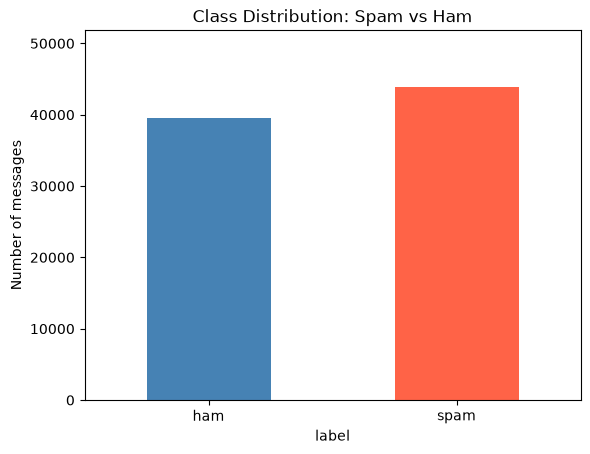

In [4]:
counts = email['label'].value_counts().sort_index()

counts.plot(kind="bar", color=["steelblue", "tomato"])
plt.xticks([0, 1], ["ham", "spam"], rotation=0)
plt.title("Class Distribution: Spam vs Ham")
plt.ylabel("Number of messages")
plt.ylim(0, counts.max() * 1.18)
plt.show()

In [5]:
def clean_text(t):
    t = str(t)[:20000]
    t = re.sub(r"http\S+|www\S+", "url", t)
    t = re.sub(r"\\+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    words = [w for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return t

email['text'] = email['text'].apply(clean_text)

email['n_words'] = email['text'].str.split().str.len()
print("\nAvg words (ham vs spam):", email.groupby('label')['n_words'].mean().round(1).to_dict())


Avg words (ham vs spam): {0: 333.6, 1: 206.9}


In [6]:
X = email['text']
y = email['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tfid = TfidfVectorizer()
X_train = tfid.fit_transform(X_train)
X_test = tfid.transform(X_test)
print("\nTF-IDF Matrix:", X_train.shape)


TF-IDF Matrix: (66758, 269575)


In [7]:
models = {
    'Naive bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(),
    'Linear SVM': LinearSVC()
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({'model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred),
                 })

results = pd.DataFrame(rows).set_index('model').round(4)
print("\n", results)


                      Accuracy  Precision  Recall      F1
model                                                   
Naive bayes            0.9762     0.9864  0.9681  0.9772
Logistic Regression    0.9856     0.9815  0.9912  0.9863
Linear SVM             0.9917     0.9902  0.9940  0.9921


In [12]:
best_name = results['F1'].idxmax()
best_model = models[best_name]
best_pred = best_model.predict(X_test)
print("\nBest Model:", best_name)
print(classification_report(y_test, best_pred, target_names=['ham', 'spam']))


Best Model: Linear SVM
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99      7908
        spam       0.99      0.99      0.99      8782

    accuracy                           0.99     16690
   macro avg       0.99      0.99      0.99     16690
weighted avg       0.99      0.99      0.99     16690



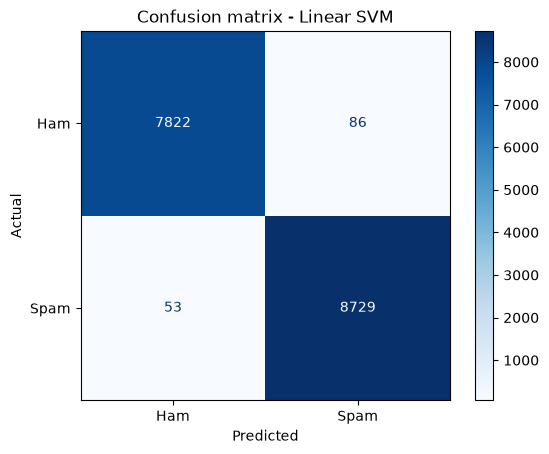

In [11]:
cm = confusion_matrix(y_test, best_pred)
ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(cmap='Blues')
plt.title("Confusion matrix - " + best_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [10]:
joblib.dump(tfid, "tfidf.joblib")
joblib.dump(best_model, "spam_model.joblib")

new_emails = [
"Get cheap medicines online now, click here to buy viagra",
"Hi team, please find the attached report for tomorrow's meeting",
]
new_vec = tfid.transform([clean_text(t) for t in new_emails])

for mail, p in zip(new_emails, best_model.predict(new_vec)):
    print("SPAM" if p == 1 else "HAM", "->", mail)

SPAM -> Get cheap medicines online now, click here to buy viagra
HAM -> Hi team, please find the attached report for tomorrow's meeting
